- **Гипотеза 1.** Как можно увеличить количество аренды электровелосипедов, например для курьеров.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

- читаю файл "../../../data_after_preprocessing/drd_with_weather.parquet"

In [2]:
drd_with_weather = pd.read_parquet('../../../data_after_preprocessing/drd_with_weather.parquet')
drd_with_weather

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,Anacostia Library,31804,11th & H St NE,31614,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301
1,docked_bike,10th & E St NW,31256,21st St & Constitution Ave NW,31261,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334
2,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333
3,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000
4,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,NaN,0,NaN,0,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800
16086668,electric_bike,NaN,0,NaN,0,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934
16086669,electric_bike,NaN,0,NaN,0,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117
16086670,electric_bike,NaN,0,NaN,0,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934


- добавляю столбец year

In [5]:
drd_with_weather['year'] = drd_with_weather['date'].dt.year

- добавляю столбец month

In [6]:
drd_with_weather['month'] = drd_with_weather['date'].dt.month

- выбираю погода wind

In [7]:
weather_wind = drd_with_weather[drd_with_weather['icon'] == 'wind']
weather_wind

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,...,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes,year,month
1322779,docked_bike,17th & K St NW / Farragut Square,31233,15th & P St NW,31201,2020-11-02 18:41:34,2020-11-02 18:49:04,casual,2020-11-02,6.5,...,40.5,-6.2,16.0,50.599998,0.0,0.0,wind,7.500000,2020,11
1322803,docked_bike,Lincoln Memorial,31258,4th St & Madison Dr NW,31288,2020-11-02 14:17:23,2020-11-02 15:52:38,casual,2020-11-02,6.5,...,40.5,-6.2,16.0,50.599998,0.0,0.0,wind,95.250000,2020,11
1322804,docked_bike,Lincoln Memorial,31258,4th St & Madison Dr NW,31288,2020-11-02 14:31:30,2020-11-02 15:52:59,casual,2020-11-02,6.5,...,40.5,-6.2,16.0,50.599998,0.0,0.0,wind,81.483330,2020,11
1322805,docked_bike,Lincoln Memorial,31258,4th St & Madison Dr NW,31288,2020-11-02 14:17:37,2020-11-02 15:30:33,casual,2020-11-02,6.5,...,40.5,-6.2,16.0,50.599998,0.0,0.0,wind,72.933334,2020,11
1322812,docked_bike,16th & Harvard St NW,31103,Georgia & New Hampshire Ave NW,31400,2020-11-02 09:33:26,2020-11-02 09:42:30,member,2020-11-02,6.5,...,40.5,-6.2,16.0,50.599998,0.0,0.0,wind,9.066667,2020,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1952636,electric_bike,Mt Vernon Trail & S. Washington St.,31929,St Asaph & Pendleton St,31043,2021-03-14 10:04:36,2021-03-14 10:10:41,casual,2021-03-14,12.4,...,24.4,-7.7,16.0,58.500000,0.0,0.0,wind,6.083333,2021,3
1952684,classic_bike,Maine Ave & 7th St SW,31609,Hains Point/Buckeye & Ohio Dr SW,31273,2021-03-14 12:54:26,2021-03-14 13:03:41,member,2021-03-14,12.4,...,24.4,-7.7,16.0,58.500000,0.0,0.0,wind,9.250000,2021,3
1952752,classic_bike,4th & East Capitol St NE,31618,Eastern Market / 7th & North Carolina Ave SE,31610,2021-03-14 15:45:08,2021-03-14 15:48:19,member,2021-03-14,12.4,...,24.4,-7.7,16.0,58.500000,0.0,0.0,wind,3.183333,2021,3
1952769,electric_bike,37th & O St NW / Georgetown University,31236,Reservoir Rd & 38th St NW,31325,2021-03-14 16:04:44,2021-03-14 16:08:44,member,2021-03-14,12.4,...,24.4,-7.7,16.0,58.500000,0.0,0.0,wind,4.000000,2021,3


- делаю pivot

In [11]:
table_share_bike = drd_with_weather.pivot_table(index='rideable_type', columns='year', values='duration_in_minutes', aggfunc='count')
table_share_bike

year,2020,2021,2022,2023,2024
rideable_type,,,,,
classic_bike,48655.0,2025621.0,2730965.0,2953466.0,1855106.0
docked_bike,1309218.0,201219.0,224796.0,113453.0,NaN
electric_bike,238881.0,522726.0,520899.0,1399800.0,1933250.0


- считаю занимаемую долю

In [12]:
shares = table_share_bike.div(table_share_bike.sum(axis=1), axis=0)
shares

year,2020,2021,2022,2023,2024
rideable_type,,,,,
classic_bike,0.005061,0.210699,0.284067,0.307211,0.192963
docked_bike,0.708188,0.108844,0.121598,0.061370,NaN
electric_bike,0.051756,0.113253,0.112857,0.303279,0.418855


- округлил до двух знаков после запятой

In [13]:
shares_percent = (shares * 100).round(2)
shares_percent

year,2020,2021,2022,2023,2024
rideable_type,,,,,
classic_bike,0.51,21.07,28.41,30.72,19.30
docked_bike,70.82,10.88,12.16,6.14,NaN
electric_bike,5.18,11.33,11.29,30.33,41.89


<Axes: xlabel='year'>

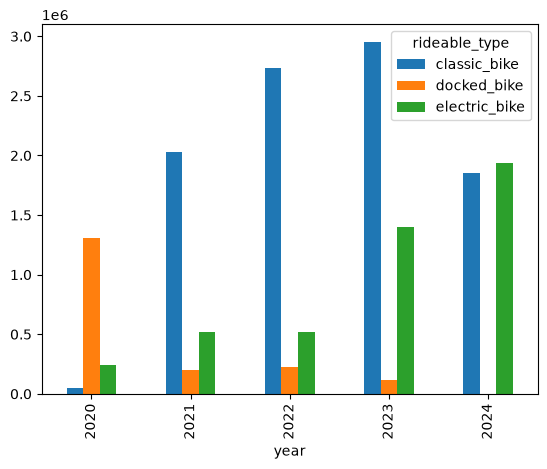

In [16]:
table_share_bike.T.plot(kind='bar')

- добавляю столбец 'year_month' что бы потом почитать за год в связке с месяцом

In [19]:
drd_with_weather

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,...,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes,year,month
0,docked_bike,Anacostia Library,31804,11th & H St NE,31614,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,...,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301,2020,5
1,docked_bike,10th & E St NW,31256,21st St & Constitution Ave NW,31261,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,...,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334,2020,5
2,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,...,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333,2020,5
3,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,...,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000,2020,5
4,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,...,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001,2020,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,NaN,0,NaN,0,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,...,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800,2024,8
16086668,electric_bike,NaN,0,NaN,0,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,...,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934,2024,8
16086669,electric_bike,NaN,0,NaN,0,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,...,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117,2024,8
16086670,electric_bike,NaN,0,NaN,0,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,...,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934,2024,8


- меняю типы данных 

In [20]:
drd_with_weather = drd_with_weather.astype({
    'year': 'string',
    'month': 'string'
})

- добавляю столбец 'year_month' что бы потом почитать за год в связке с месяцом

In [21]:
drd_with_weather['year_month'] = drd_with_weather['year'] + '-' + drd_with_weather['month']

- делаю pivot

In [24]:
table_share_bike_months = drd_with_weather.pivot_table(
    index='rideable_type', columns='year_month', values='duration_in_minutes', aggfunc='count'
)

table_share_bike_months

year_month,2020-10,2020-11,2020-12,2020-5,2020-6,2020-7,2020-8,2020-9,2021-1,2021-10,...,2023-8,2023-9,2024-1,2024-2,2024-3,2024-4,2024-5,2024-6,2024-7,2024-8
rideable_type,,,,,,,,,,,,,,,,,,,,,
classic_bike,NaN,NaN,48655.0,NaN,NaN,NaN,NaN,NaN,68686.0,257214.0,...,309407.0,298619.0,116669.0,156803.0,218719.0,260305.0,276281.0,297487.0,274465.0,254377.0
docked_bike,178777.0,134735.0,28510.0,148482.0,213278.0,211661.0,200686.0,193089.0,4606.0,22808.0,...,14901.0,4610.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
electric_bike,49594.0,40082.0,28089.0,NaN,63.0,15780.0,49607.0,55666.0,26772.0,48269.0,...,145692.0,146779.0,122121.0,161840.0,218183.0,229880.0,239191.0,286870.0,314978.0,360187.0


- делаю сортировку по заголовку year_month

In [25]:
table_share_bike_months = table_share_bike_months.reindex(
    sorted(
        table_share_bike_months.columns,
        key=lambda x: pd.to_datetime(x, format='%Y-%m')
    ),
    axis=1
)

table_share_bike_months

year_month,2020-5,2020-6,2020-7,2020-8,2020-9,2020-10,2020-11,2020-12,2021-1,2021-2,...,2023-11,2023-12,2024-1,2024-2,2024-3,2024-4,2024-5,2024-6,2024-7,2024-8
rideable_type,,,,,,,,,,,,,,,,,,,,,
classic_bike,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48655.0,68686.0,52218.0,...,197083.0,137401.0,116669.0,156803.0,218719.0,260305.0,276281.0,297487.0,274465.0,254377.0
docked_bike,148482.0,213278.0,211661.0,200686.0,193089.0,178777.0,134735.0,28510.0,4606.0,2760.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
electric_bike,NaN,63.0,15780.0,49607.0,55666.0,49594.0,40082.0,28089.0,26772.0,22471.0,...,161453.0,139614.0,122121.0,161840.0,218183.0,229880.0,239191.0,286870.0,314978.0,360187.0


- вывожу график

<Axes: xlabel='year_month'>

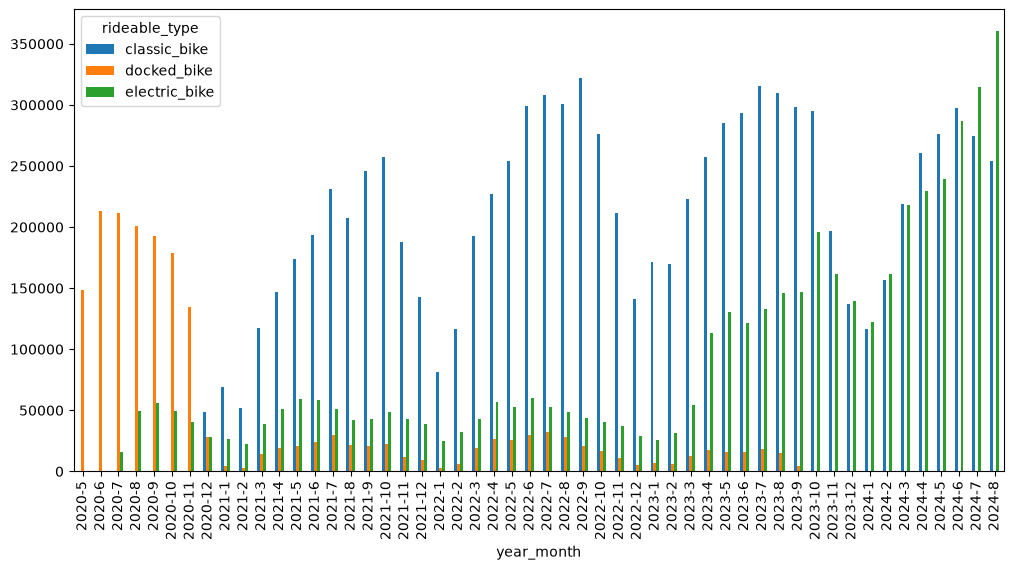

In [26]:
table_share_bike_months.T.plot(kind='bar', figsize=(12, 6))

### Вывод по гипотезе 1 - Как можно увеличить количество аренды электровелосипедов, например для курьеров.

За последние два года видно что доля элетровелосипедов уже значительно стала больше.
- Уже видно что доминация электрических велосипедов последнии два месяца превзошли классические велосипеды
- Ответом на гипотезу будет следующим что долю элетрических велосипедов можно раскачать до 60 % занимаемой доли

- Что касаемо аренды электрических байков, например для курьеров, здесь нужно посмотреть как развивалась доставка после пандемии